# GeoMx Analysis and Data Visualization

**Author: Fabien Bertillot**  

---
## 1. Objective

Analysis of GeoMx spatial transcriptomic data from colorectal tumor samples across 8 patients, with focus on tissue architecture, molecular clustering, and pathway enrichment.

## 2. Dependencies

- Libraries: `scanpy`, `pandas`, `community`, `matplotlib`, `seaborn`, `networkx`, `seaborn`, `gseapy`, `pydeseq2`
- Files required:  
  - `data.h5ad` — Dataset format must be an Anndata
  - `gene_sets.json` —  A nested dictionnary of gene set signatures
---

## 3. Notebook Roadmap

1. **Load Dependencies**  
2. **Load Dataset**  
   - Read `data.h5ad`  
   - Read `gene_sets.json`  
   - Filter some samples and define some colormaps
3. **Scanpy Preprocessing Parameters**  
4. **Harmony integration for batch correction**  
    - Preprocessing and Batch correction
    - Leiden clustering
    - UMAP plots
5. **Preprocessing and clustering (without batch correction)**  
    - Preprocessing and Leiden clustering
    - UMAP plots
6. **Spatial Clustering**  
    - Cluster GeoMx ROIs into spatial regions with Louvain clustering
    - Plot molecular clusters and architectures across spatial clusters
7. **Plot Number of Regions Across Patients** 
8. **Stacked Bar Plots (patients, architectures, molecular clusters)** 
9. **Projection of GeoMX ROIs Colored by Tissue Architecture and Molecular Clusters** 
10. **Compute Differential Gene Expression with pydeseq2**
11. **Gene Set Enrichment Analysis (GSEA)**
    - Compute GSEA for given signatures
    - Plots
12. **Box Plots (Gene expression across patients, architectures)**

---

## 1) Load Dependencies

In [3]:
import pandas as pd
import anndata as ad
import numpy as np 
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import community as community_louvain
import seaborn as sns
import json
import os
# from adjustText import adjust_text
from geomxlib import *
import matplotlib
import gseapy as gp

c:\ProgramData\Anaconda3\envs\bioinfo\lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [4]:
from watermark import watermark
%reload_ext watermark
%watermark --iversions
# %watermark -iv

pandas    : 2.2.3
matplotlib: 3.7.0
seaborn   : 0.13.2
scanpy    : 1.10.2
networkx  : 3.4.2
community : 0.16
adjustText: 1.2.0
watermark : 2.5.0
numpy     : 1.23.5
json      : 2.0.9
gseapy    : 1.1.3
sklearn   : 1.5.2
anndata   : 0.10.8



## 2) Load Dataset 

In [5]:
# -- Load anndata and get sets

DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\data'
EXPRS_PATH = os.path.join(DIR, 'geomx_crc_dataset.h5ad')
GENE_SETS_PATH = os.path.join(DIR, 'gene_sets.json')

adata = sc.read(EXPRS_PATH)

with open(GENE_SETS_PATH, 'r') as file:
    gene_sets = json.load(file)
    
    
# -- Filter some samples 
adata_raw = adata[adata.obs['segment'] == 'Segment 1'] # Filter stroma
adata = adata_raw.copy()

# -- Define some colormaps 

# Architectures
architecture_order = ['solid', 'glandular dense', 'glandular', 'glandular infiltrated', 'budding', 'fragmented']
architecture_palette = ['#009ADE','#00CD6C', '#FFC61E', '#FED976','#F28522','#FF1F5B']
architecture_colormap = dict(zip(architecture_order, architecture_palette))

# Patients
patient_order = ['K13956-15', 'K10985-13', 'K10821-03','K14159-12', 'K19044-13', 'K11178-10', 'K5631-07', 'K15357-10']
patient_palette = []
patient_colormap = dict(zip(patient_order, sns.color_palette('Set2')))

['Non-matrisome' 'Proteoglycans' 'ECM Regulators' 'ECM Glycoproteins'
 'Secreted Factors' 'ECM-affiliated Proteins' 'Collagens']
['Non-matrisome' 'Core matrisome' 'Matrisome-associated']


In [6]:
adata

AnnData object with n_obs × n_vars = 249 × 12729
    obs: 'slide_id', 'roi_id', 'area_fraction', 'mean_CD45', 'mean_aSMA', 'mean_H3K9', 'mean_RNApolII', 'mean_LMNAC', 'mean_H3K9_sn', 'mean_RNApolII_sn', 'mean_LMNAC_sn', 'lap_var', 'qc_pass', 'sample_id', 'segment', 'patient_id', 'region', 'index', 'x_centroid', 'y_centroid', 'x_orientation', 'y_orientation', 'major_axis', 'minor_axis', 'perimeter', 'convex_area', 'area', 'circularity', 'roundness', 'solidity', 'aspect_ratio', 'compactness', 'efc_ratio', 'isin_tumor', 'X', 'Y', 'Height', 'Width', 'hollow_ratio', 'area_fraction_class', 'mean_CD45_class', 'mean_aSMA_class', 'mean_H3K9_sn_class', 'mean_RNApolII_sn_class', 'mean_LMNAC_sn_class', 'hollow_ratio_class', 'circularity_class', 'solidity_class', 'patients_ordered', 'architectures'
    layers: 'processed', 'raw'

## 3) Scanpy Preprocessing Parameters

In [ ]:
TOP_GENES = 2000
N_NEIGHBORS = 10
N_PCS = 30
RES = 2
KEY_LEIDEN = 'leiden_2'

## 4) Harmony Integration

In [77]:
# -- Batch correction with harmony

adata_raw_hry = adata_raw.copy()

sc.pp.log1p(adata_raw_hry, layer='processed')
adata_raw_hry.X = adata_raw_hry.layers['processed']    

sc.pp.highly_variable_genes(adata_raw_hry, n_top_genes=TOP_GENES, batch_key="patient_id")

sc.pp.pca(adata_raw_hry,  svd_solver='arpack')
sc.external.pp.harmony_integrate(adata_raw_hry , key='patient_id')

sc.pp.neighbors(adata_raw_hry, use_rep='X_pca_harmony', n_neighbors=N_NEIGHBORS, n_pcs=N_PCS)
sc.tl.umap(adata_raw_hry)

2024-09-16 12:33:28,444 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
c:\ProgramData\anaconda3\envs\bioinfo\lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
2024-09-16 12:33:28,477 - harmonypy - INFO - sklearn.KMeans initialization complete.
2024-09-16 12:33:28,480 - harmonypy - INFO - Iteration 1 of 10
2024-09-16 12:33:28,501 - harmonypy - INFO - Iteration 2 of 10
2024-09-16 12:33:28,539 - harmonypy - INFO - Iteration 3 of 10
2024-09-16 12:33:28,554 - harmonypy - INFO - Iteration 4 of 10
2024-09-16 12:33:28,569 - harmonypy - INFO - Iteration 5 of 10
2024-09-16 12:33:28,582 - harmonypy - INFO - Iteration 6 of 10
2024-09-16 12:33:28,592 - harmonypy - INFO - Iteration 7 of 10
2024-09-16 12:33:28,603 - harmonypy - INFO - Iteration 8 of 10
2024-09-16 12:

In [ ]:
# -- Leiden clustering

sc.tl.leiden(adata_raw_hry, resolution=RES, key_added=KEY_LEIDEN)

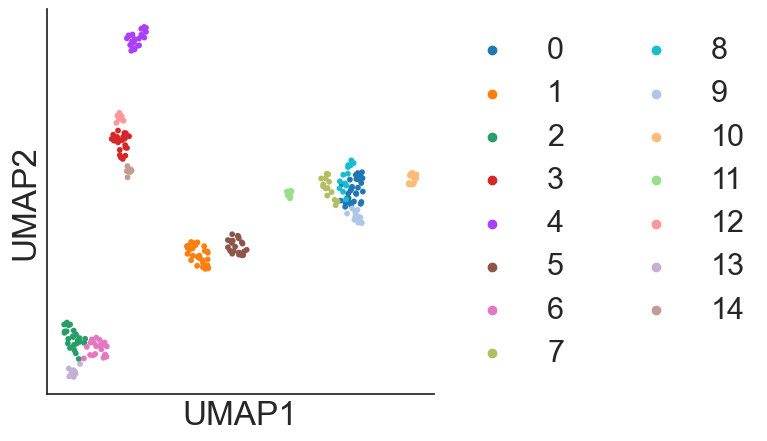

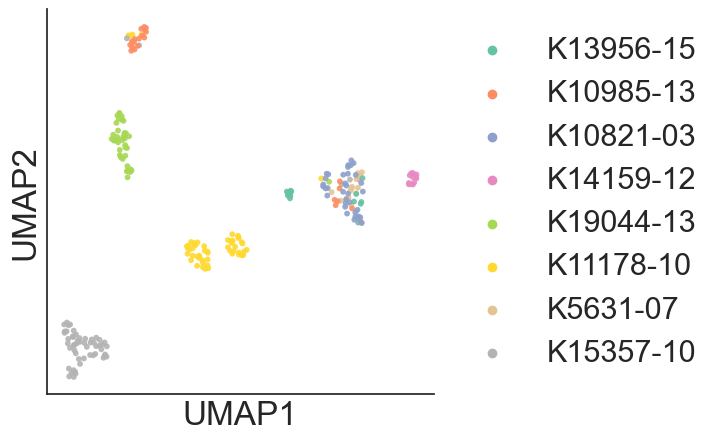

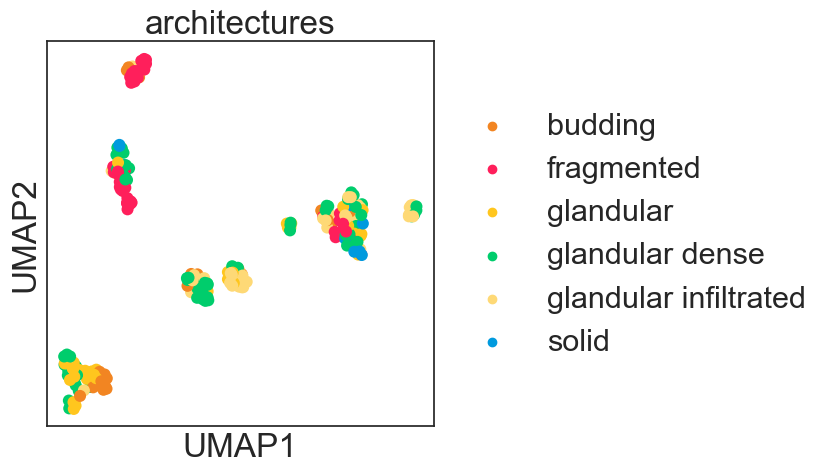

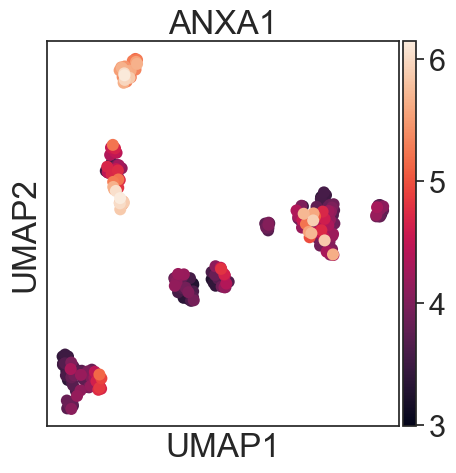

In [78]:
# -- UMAP plots

sns.set(font_scale = 2)
sns.set_style('white', rc={
'xtick.bottom': True,
'ytick.left': True,
})
plt.rcParams["figure.figsize"] = (5,5)
sc.pl.umap(adata_raw_hry, color=[KEY_LEIDEN], show=False,size=70,
        #    palette={str(i):c for i,c in enumerate(sns.color_palette('tab20', 20))}
           )
ax = plt.gca()

# Remove the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.title('')

plt.show()
sc.pl.umap(adata_raw_hry, color=['patients_ordered'], size=70, show=False, alpha=0.9, palette=patient_colormap)
ax = plt.gca()

# Remove the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.title('')

sc.pl.umap(adata_raw_hry, color=['architectures'], palette=architecture_colormap, size=300)
sc.pl.umap(adata_raw_hry, color=['ANXA1'], palette=architecture_colormap, size=300)

## 5) Preprocessing and Clustering

### 5.a) Preprocessing and clustering

In [5]:
# -- Leiden preprocessing

adata = scanpy_preprocessing(adata, 
                             layer='processed',
                             n_neighbors=N_NEIGHBORS,
                             n_pcs=N_PCS)



c:\ProgramData\Anaconda3\envs\bioinfo\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\Anaconda3\envs\bioinfo\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\ProgramData\Anaconda3\envs\bioinfo\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\ProgramData\Anaconda3\envs\bioinfo\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\Anaconda3\envs\bioinfo\lib\subprocess.py", line 1440, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess

In [5]:
# -- Leiden clustering

sc.tl.leiden(adata, resolution=RES, key_added=KEY_LEIDEN)

C:\Users\fbertil\AppData\Local\Temp\ipykernel_22476\3232411215.py:4: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=RES, key_added=KEY_LEIDEN)


### 5.b) UMAP projection

Text(0.5, 1.0, '')

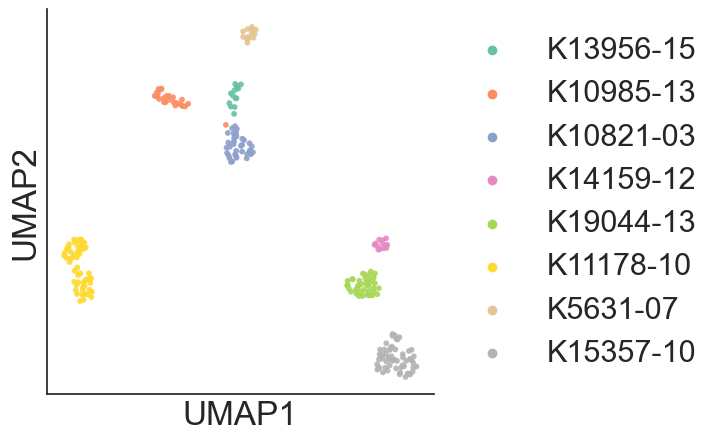

In [79]:
sns.set(font_scale = 2)
sns.set_style('white', rc={
'xtick.bottom': True,
'ytick.left': True,
})
plt.rcParams["figure.figsize"] = (5,5)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.pl.umap(adata, color=['patients_ordered'], size=70, show=False, alpha=0.9, palette=patient_colormap)
ax = plt.gca()

# Remove the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.title('')

# OUT_DIR = r'D:\CRC Figures\geomx analysis\Figures'
# out_path = os.path.join(OUT_DIR, f'tumor_UMAP_patients.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')


### 5.c) Project molecular clusters on UMAP

Text(0.5, 1.0, '')

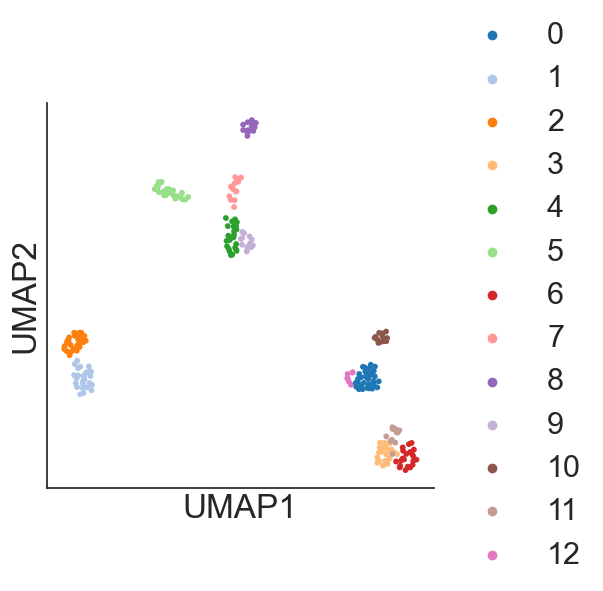

In [80]:
sns.set(font_scale = 2)
sns.set_style('white', rc={
'xtick.bottom': True,
'ytick.left': True,
})
plt.rcParams["figure.figsize"] = (5,5)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

leiden_colormap = {str(i):c for i,c in enumerate(sns.color_palette('tab20', 20))}

sc.pl.umap(adata, color=[KEY_LEIDEN], show=False,size=70,
           palette=leiden_colormap
           )
ax = plt.gca()

# Remove the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.title('')

# plt.show()

# OUT_DIR = r'D:\CRC Figures\geomx analysis\Figures'
# out_path = os.path.join(OUT_DIR, f'tumor_UMAP_molecular_clusters.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')

## 6) Spatial Clustering

### 6.a) Louvain clustering

In [36]:
def louvain_clustering(adata, patient_id_col, x_col, y_col):
    # Get unique patient IDs
    patient_ids = adata.obs[patient_id_col].unique()
    
    # Prepare a Series to store combined cluster labels
    combined_clusters = pd.Series(index=adata.obs.index, dtype='object')
    
    for patient_id in patient_ids:
        # Subset the data for the current patient
        subset = adata[adata.obs[patient_id_col] == patient_id]
        
        # Extract the spatial coordinates
        coords = subset.obs[[x_col, y_col]].values
        
        # Create a nearest neighbors graph
        neighbors = NearestNeighbors(n_neighbors=10).fit(coords)
        graph = neighbors.kneighbors_graph(coords)
        
        # Convert the neighbors graph to a NetworkX graph
        # G = nx.from_scipy_sparse_matrix(graph)
        graph_coo = graph.tocoo()
        G = nx.Graph()
        G.add_edges_from(
            (row, col, {"weight": weight})
            for row, col, weight in zip(graph_coo.row, graph_coo.col, graph_coo.data)
            if row != col
)
        
        # Run Louvain clustering
        partition = community_louvain.best_partition(G)
        
        # Combine patient ID with cluster value
        combined_cluster_labels = {idx: f"{patient_id}_{cluster}" for idx, cluster in partition.items()}
        
        # Store the combined cluster labels
        clusters_subset = pd.Series(combined_cluster_labels, name='combined_cluster')
        clusters_subset.index = subset.obs.index
        combined_clusters.update(clusters_subset)
    
    # Add the combined clusters back to the original AnnData object
    adata.obs['combined_cluster'] = combined_clusters
    
    return adata

In [37]:
adata = louvain_clustering(adata, 'patient_id', 'X', 'Y')

### 6.b) Plot leiden cluster distribution across spatial clusters

Text(0, 0.5, 'count')

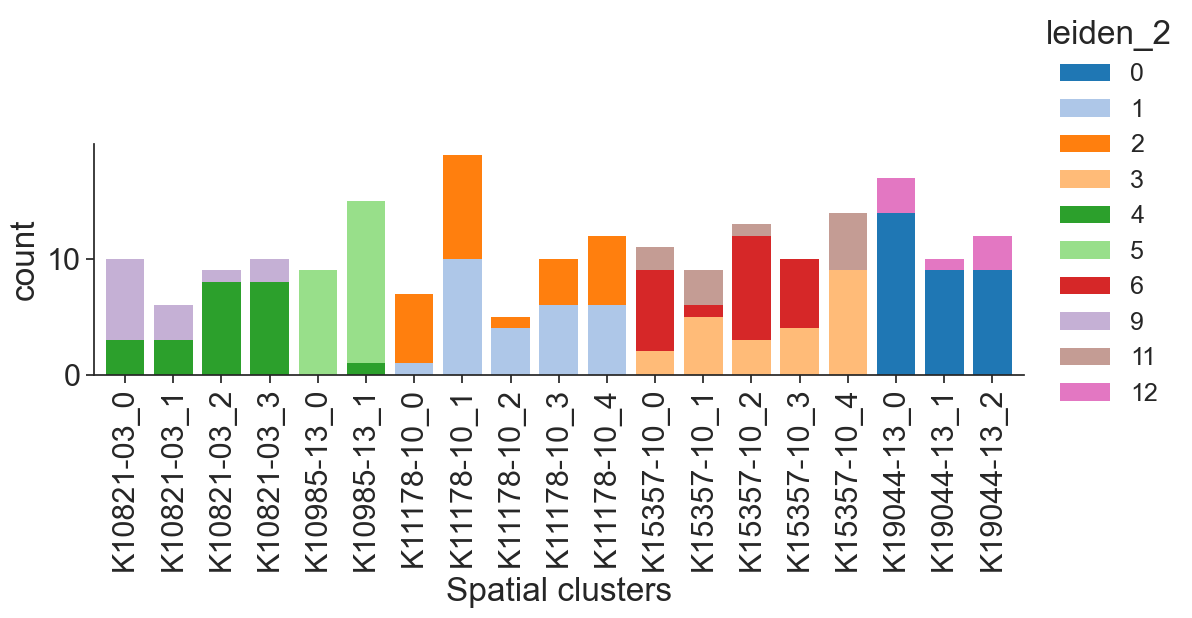

In [42]:
selected_patients = [
                    #  'K13956-15',
                     'K10985-13', 
                     'K10821-03',
                    #  'K14159-12', 
                     'K19044-13', 
                     'K11178-10', 
                    #  'K5631-07', 
                     'K15357-10'
                     ]

adata_filt = adata[adata.obs['patient_id'].isin(selected_patients)]
ax = barplot(adata_filt, 
             x='combined_cluster',
             labels='leiden_2', 
            #  bar_order = patient_order,
             colormap = leiden_colormap,
             norm=False,
             figsize = (12,3),
             kind='bar',
             rotation=90
            )


plt.xlabel('Spatial clusters')
plt.ylabel('count')

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\Figures\Sup'
# out_path = os.path.join(OUT_DIR, f'molecular_clusters_across_spatial_clusters.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')


### 6.c) Plot architecture  distribution across spatial clusters

Text(0, 0.5, 'count')

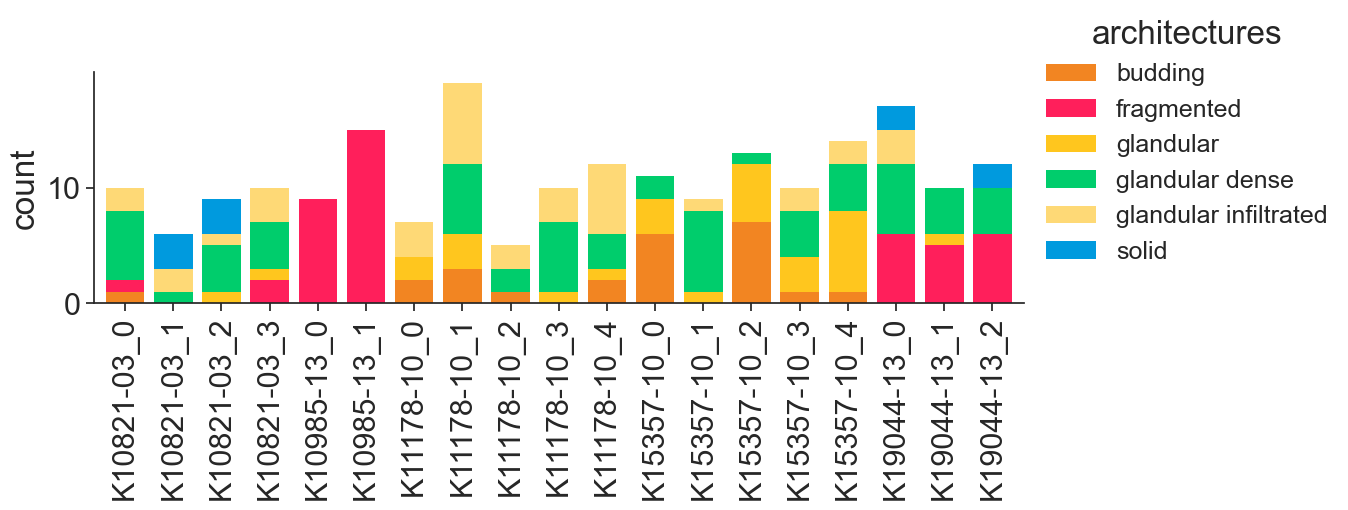

In [43]:
# -- Plot architecture  distribution across spatial clusters
selected_patients = [
                    #  'K13956-15',
                     'K10985-13', 
                     'K10821-03',
                    #  'K14159-12', 
                     'K19044-13', 
                     'K11178-10', 
                    #  'K5631-07', 
                     'K15357-10'
                     ]

adata_filt = adata[adata.obs['patient_id'].isin(selected_patients)]

ax = barplot(adata_filt, 
             x='combined_cluster',
             labels='architectures', 
            #  bar_order = patient_order,
             colormap = architecture_colormap,
             norm=False,
             figsize = (12,3),
             kind='bar',
             rotation=90
            )


plt.xlabel('')
plt.ylabel('count')

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\Figures\Sup'
# out_path = os.path.join(OUT_DIR, f'architectures_across_spatial_clusters.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')

## 7) Plot Number of Regions Across Patients

(0.0, 50.0)

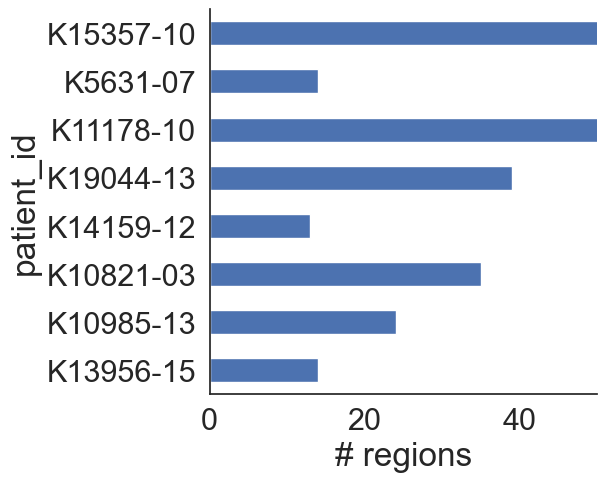

In [44]:
patient_count = adata.obs['patient_id'].value_counts()

# Plotting
plt.figure(figsize=(5, 5))
patient_count = patient_count.reindex(patient_order)

patient_count.plot(kind='barh')
plt.xlabel('# regions')
sns.despine()
plt.xlim([0,50])
# OUT_DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\Figures\Sup'
# out_path = os.path.join(OUT_DIR, f'stroma_nb_rois_per_patient.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')


(0.0, 50.0)

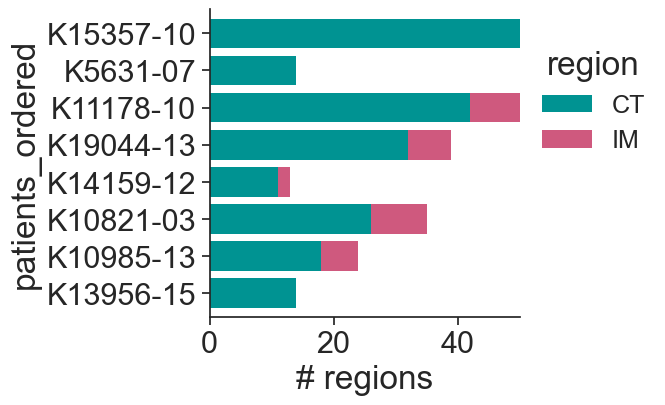

In [46]:
ct_im_colormap = {'CT':'#009392', 'IM':'#CF597E'}

ax = barplot(adata_raw, 
             x='patients_ordered',
             labels='region', 
            #  bar_order = patient_order,
            norm=False,
             colormap = ct_im_colormap,
             figsize = (4,4),
             kind='barh'
            )

plt.xlabel('# regions')
plt.xlim([0,50])

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\Figures\Sup'
# out_path = os.path.join(OUT_DIR, f'stroma_nb_rois_per_patient.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')


## 8) Stacked Bar Plots (patients, architectures, molecular clusters) 

Text(0, 0.5, '')

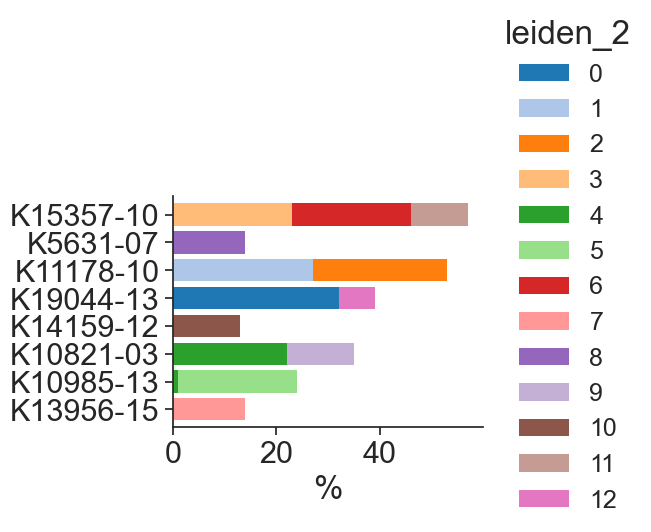

In [47]:
# -- Leiden cluster distribution across patients

leiden_colormap = {str(i):c for i,c in enumerate(sns.color_palette('tab20', 20))}

ax = barplot(adata, 
             x='patients_ordered',
             labels='leiden_2', 
            #  bar_order = patient_order,
            norm=False,
             colormap = leiden_colormap,
             figsize = (4,3),
             kind='barh'
            )


plt.xlabel('%')
plt.ylabel('')

# OUT_DIR = r'D:\CRC Figures\geomx analysis\Figures'
# out_path = os.path.join(OUT_DIR, f'distribution_clusters_per_patient.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')

# plt.xticks(rotation=90, ha='center')  

Text(0, 0.5, 'Molecular clusters')

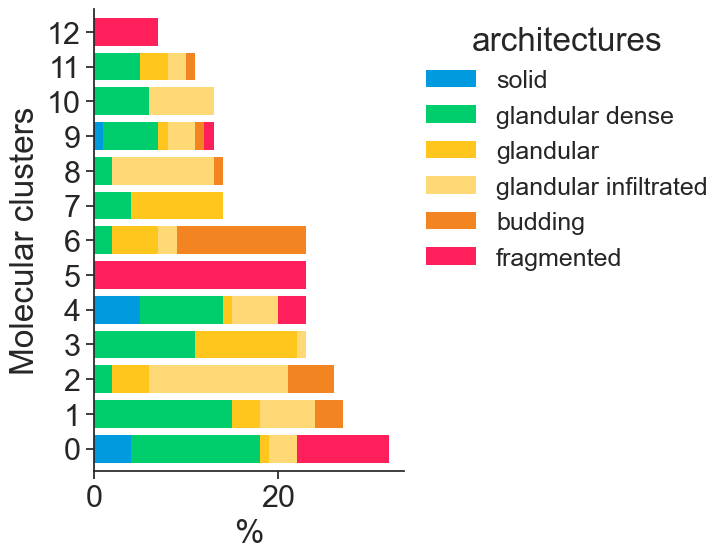

In [48]:
# Distribution of architectures across molecular (leiden) clusters
x = KEY_LEIDEN
ax = barplot(adata, 
             x=x,
             labels='architectures', 
             bar_order = architecture_order,
             colormap = architecture_colormap,
             figsize = (4,6),
             norm=False,
             kind='barh'
            )

plt.xlabel('%')
plt.ylabel('Molecular clusters')

# OUT_DIR = r'D:\CRC Figures\geomx analysis\Figures'
# out_path = os.path.join(OUT_DIR, f'distribution_architecture_per_molecular_cluster.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')

Text(0, 0.5, '')

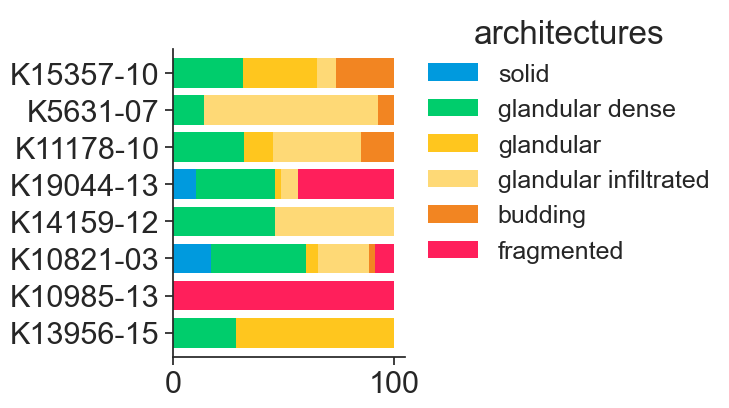

In [49]:
# -- Architecture distribution across patients

x = 'patient_id'
ax = barplot(adata, 
             x=x,
             x_order = patient_order,
             labels='architectures', 
             bar_order = architecture_order,
             colormap = architecture_colormap,
             figsize = (3,4),
             kind='barh'
            )

plt.xlabel('')
plt.ylabel('')

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\Figures\Sup'
# out_path = os.path.join(OUT_DIR, f'distribution_architecture_per_patient.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')


## 9) Projection of GeoMX ROIs Colored by Tissue Architecture and Molecular Clusters

projection on K11178-10


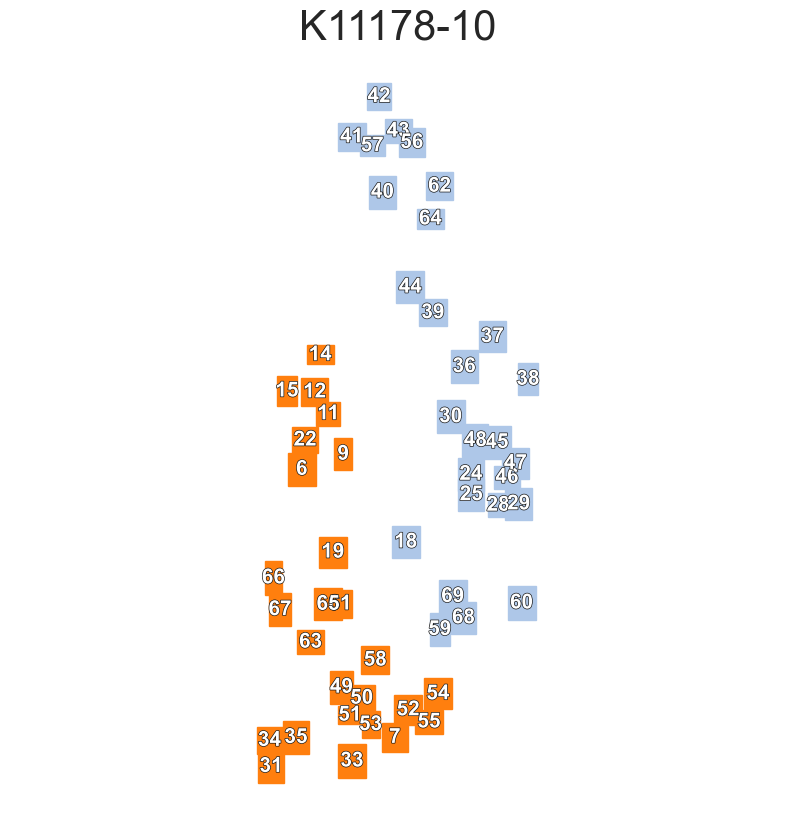

In [54]:
# -- Plot leiden cluster spatial distribution of a given patient

PATIENT_ID = 'K11178-10'
print(f'projection on {PATIENT_ID}')


project_data_into_tissue(adata, 
                        patient_id=PATIENT_ID, 
                        color=KEY_LEIDEN, 
                        colormap=leiden_colormap,
                        fontsize=18)

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\Figures\Sup'
# out_path = os.path.join(OUT_DIR, f'molecular_cluster_projection_{PATIENT_ID}.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')

projection on K11178-10


<Figure size 300x400 with 0 Axes>

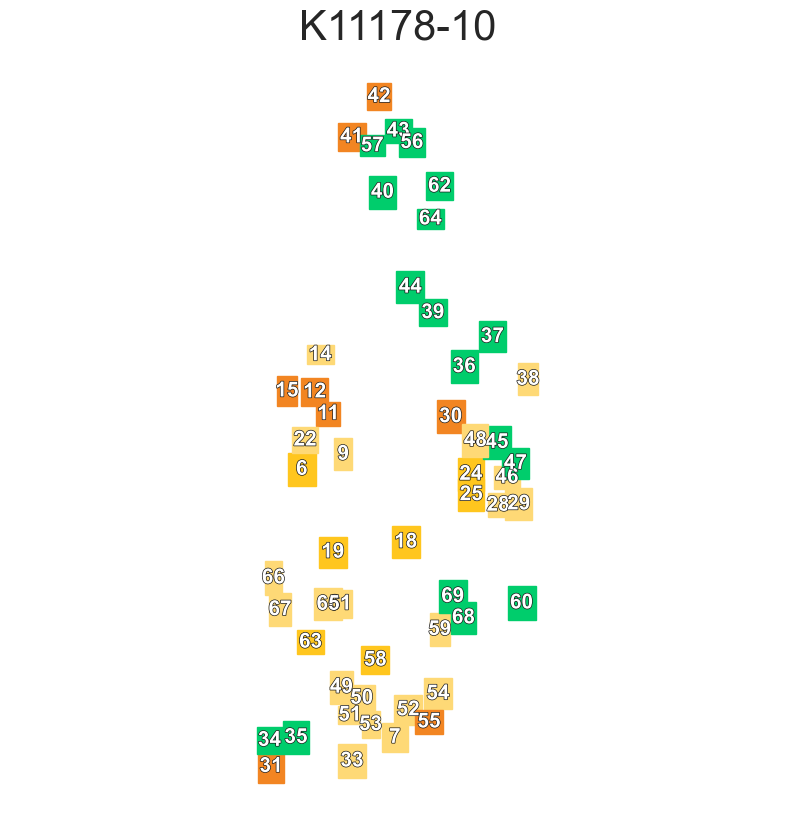

In [24]:
# -- Plot architecture spatial distribution of a given patient

PATIENT_ID = 'K11178-10'
print(f'projection on {PATIENT_ID}')

plt.figure(2)

project_data_into_tissue(adata, 
                        patient_id=PATIENT_ID, 
                        color='architectures', 
                        colormap=architecture_colormap,
                        fontsize=18)

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\geomx analysis\Figures\Sup'
# out_path = os.path.join(OUT_DIR, f'architecture_projection_{PATIENT_ID}.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')


## 10) Compute DGE with pydeseq2

In [ ]:
# -- Compute DGE with pydeseq2 (can take up to 10min)

condition = 'architectures'
OUT_PATH = r'C:\Users\fbertil\CRC Figures\geomx analysis\raw_dges_architectures_simplified.csv'

counts_df = pd.DataFrame(data=adata_raw.X, 
                         index=adata_raw.obs['sample_id'],
                         columns=adata_raw.var_names)

metadata = pd.DataFrame({
                         condition: adata_raw.obs[condition].values,
                         'patient_id': adata_raw.obs['patient_id'].values
                        },  index=adata_raw.obs['sample_id'])


conditions = adata_raw.obs[condition].unique()

dfs_dge = []

for cond in conditions:
    print(cond)
    df_cond = compute_dge_from_pydeseq2(counts_df, metadata, condition, cond)
    dfs_dge.append(df_cond)
    
    
dfs_dge = pd.concat(dfs_dge).reset_index(drop=True)

dfs_dge.to_csv(OUT_PATH, index=False)

## 11) GSEA Analysis

In [10]:
# -- Load DGE file

df_dge = pd.read_csv(r'C:\Users\fbertil\CRC Figures\geomx analysis\data\raw_dges_architectures.csv')
df_dge.head(10)

,Gene,scores,lfc,lfcSE,stat,pvals,pval_adj,neg_log10_pval,group
0,A2M,72.10812,0.027756,0.068788,0.572923,0.566697,0.701087,0.246649,glandular infiltrated
1,ACADM,94.02323,-0.048456,0.071608,-0.954099,0.340034,0.496424,0.468478,glandular infiltrated
2,ACADS,72.77211,0.126356,0.051059,2.820519,0.004795,0.022306,2.319248,glandular infiltrated
3,ACAT1,127.89381,-0.385883,0.103309,-4.346928,0.000014,0.000318,4.859939,glandular infiltrated
4,ACVRL1,58.10661,0.235743,0.082229,3.466311,0.000528,0.004320,3.277653,glandular infiltrated
5,PSEN1,81.32290,-0.174070,0.057154,-3.516481,0.000437,0.003810,3.359212,glandular infiltrated
6,ADA,66.28714,0.130790,0.063107,2.516848,0.011841,0.043562,1.926612,glandular infiltrated
7,SGCA,77.03412,0.022246,0.043910,0.581183,0.561117,0.696961,0.250947,glandular infiltrated
8,AGL,57.33321,-0.043072,0.039088,-1.202619,0.229124,0.377885,0.639930,glandular infiltrated
9,ABCD1,71.80027,0.134979,0.056236,2.820857,0.004790,0.022291,2.319705,glandular infiltrated


In [6]:
# Add human fetal signature

df_fetal = pd.read_excel(r'C:\Users\fbertil\CRC Figures\geomx analysis\data\fetal_signature.xlsx')
robust_genes = df_fetal[df_fetal['Robust']==True]['Gene'].values   
gene_sets['STEM_signatures']['Fetal (human)'] =robust_genes 
gene_sets['STEM_signatures'].pop("Fetal", None)
gene_sets['STEM_signatures'].keys()

In [11]:
# -- Compute GSEA

stratify='architectures'
gene_set = gene_sets['STEM_signatures']

conditions=architecture_order
# conditions=['glandular','solid','fragmented']

df_gsea = []
for condition in conditions:
    df_rnk = df_dge[df_dge['group']==condition]
    # df_rnk = df_rnk[df_rnk['lfc']>0.1]
    # df_rnk = df_rnk[df_rnk['pval_adj']<0.05]
    df_rnk = df_rnk.sort_values(by='pval_adj')

    df_rnk = df_rnk[['Gene','lfc']].reset_index(drop=True)

    pre_res = gp.prerank(rnk=df_rnk, # or rnk = rnk,
                        gene_sets=gene_set,
                        threads=4,
                        min_size=5,
                        max_size=1000,
                        permutation_num=1000, # reduce number to speed up testing
                        outdir=None, # don't write to disk
                        seed=6,
                        verbose=True, # see what's going on behind the scenes
                        )

    pre_res.res2d['group'] = [condition]*len(pre_res.res2d)
    df_gsea.append(pre_res.res2d)

df_gsea = pd.concat(df_gsea).reset_index(drop=True)

2025-04-09 15:03:35,997 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-04-09 15:03:36,000 [INFO] Parsing data files for GSEA.............................
2025-04-09 15:03:36,004 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2025-04-09 15:03:36,006 [INFO] 0007 gene_sets used for further statistical testing.....
2025-04-09 15:03:36,008 [INFO] Start to run GSEA...Might take a while..................
2025-04-09 15:03:38,065 [INFO] Congratulations. GSEApy runs successfully................

2025-04-09 15:03:38,089 [WARNING] Duplicated values found in preranked stats: 0.02% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-04-09 15:03:38,091 [INFO] Parsing data files for GSEA.............................
2025-04-09 15:03:38,095 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
20

C:\Users\fbertil\AppData\Local\Temp\ipykernel_14548\1877696205.py:39: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_pivot_pval_sizes = df_pivot_pval.applymap(map_pvalues_to_sizes)
meta NOT subset; don't know how to subset; dropped


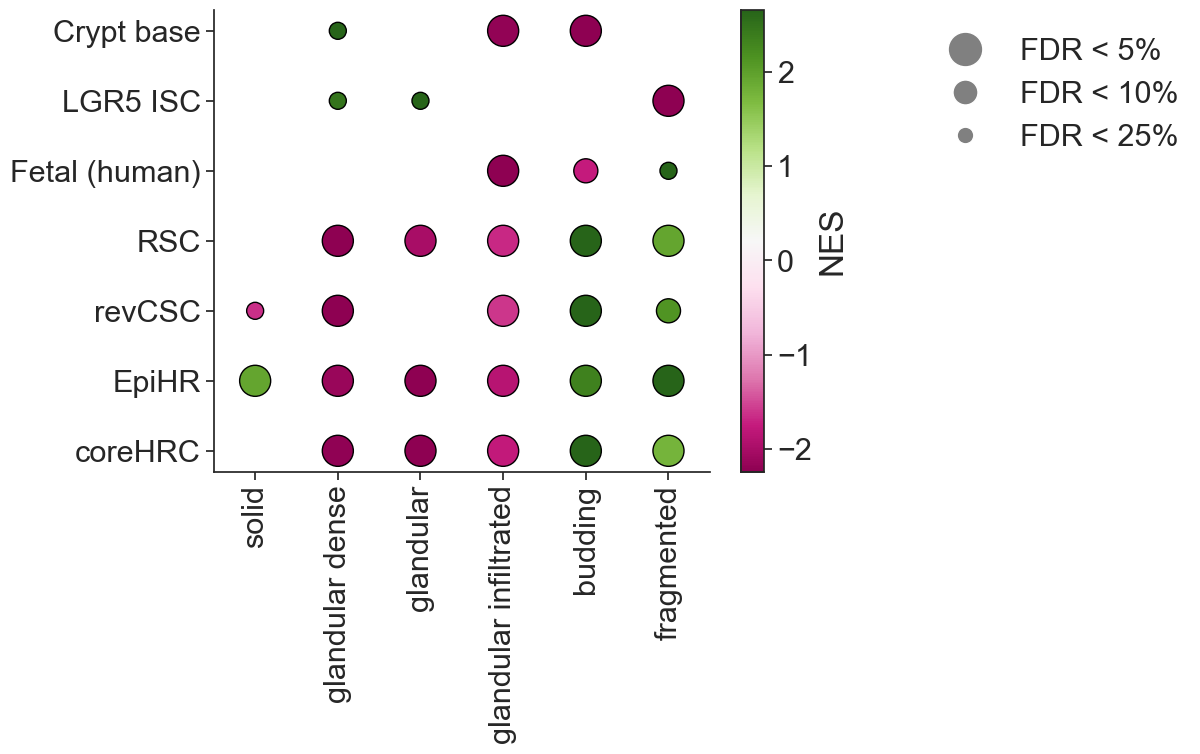

In [18]:
# -- Plot GSEA

index_order = ['Crypt base', 'LGR5 ISC', 'Fetal (human)', 'RSC', 'revCSC', 'EpiHR', 'coreHRC']
# index_order = ['Wound response', 'Mesenchymal', 'Matrix remodeling', 'TGFB activation',  'EMT activation', 'EMT Hallmark', 'pEMT', 'EMT-II (MP13)']

FIG_SIZE = (8, 6)

def map_pvalues_to_sizes(pval):
    if pval < 0.05:
        return 500
    elif pval < 0.1:
        return 300
    elif pval < 0.25:
        return 150
    # elif pval < 0.05:
    #     return 100
    elif pval > 0.25:
        return 0
    else:
        return 0

df_pivot_es = df_gsea.pivot(index="Term", columns="group", values="NES").reset_index()
df_pivot_pval = df_gsea.pivot(index="Term", columns="group", values="FDR q-val").reset_index()

df_pivot_es = df_pivot_es[df_pivot_es['Term'].isin(index_order)]
df_pivot_pval = df_pivot_pval[df_pivot_pval['Term'].isin(index_order)]
# df_pivot_es = df_pivot_es.reindex(index_order)
# df_pivot_pval = df_pivot_pval.reindex(index_order)

df_pivot_es.set_index('Term', inplace=True)
df_pivot_pval.set_index('Term', inplace=True)
df_pivot_es = df_pivot_es.reindex(index_order)
df_pivot_pval = df_pivot_pval.reindex(index_order)


df_pivot_es = df_pivot_es[architecture_order]
df_pivot_pval = df_pivot_pval[architecture_order]

df_pivot_pval_sizes = df_pivot_pval.applymap(map_pvalues_to_sizes)

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sns.set(font_scale = 2)
sns.set_style('white', rc={
    'xtick.bottom': True,
    'ytick.left': True,
})
fig, ax = plt.subplots(figsize=FIG_SIZE)


terms = df_pivot_es.index
categories = df_pivot_es.columns

for i, term in enumerate(terms):
# for i, term in zip([0.3,0.7],terms):
    y = np.repeat(i, len(categories))  # Y position for all categories
    x = np.arange(len(categories))     # X position for each category
    color_values = df_pivot_es.loc[term]  # Color from the expression score DataFrame
    dot_sizes = df_pivot_pval_sizes.loc[term]  # Sizes from the custom function

    scatter = ax.scatter(x, y, s=dot_sizes, c=color_values, cmap='PiYG', edgecolor='black', alpha=1)

# Adding labels and formatting
ax.set_yticks(np.arange(len(terms)))
# ax.set_yticks([0.3,0.7])

ax.set_yticklabels(terms)
# ax.set_ylim([-0.5,1.5])
ax.set_xlim([-0.5,5.5])

ax.set_xticks(np.arange(len(categories)))
ax.set_xticklabels(categories, rotation=90, ha='center')
ax.invert_yaxis()  # Invert axis to have terms on y-axis in descending order

# Color bar for expression scores
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('NES')

# Legend
legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='FDR < 5%', markerfacecolor='gray', markersize=25),
                   plt.Line2D([0], [0], marker='o', color='w', label='FDR < 10%', markerfacecolor='gray', markersize=18),
                   plt.Line2D([0], [0], marker='o', color='w', label='FDR < 25%', markerfacecolor='gray', markersize=12)]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(2, 1), frameon=False)


# plt.title('Dot Plot of Terms vs Categories')
# plt.grid(True, which='both', ls='', lw=0.5)
# plt.show()
sns.despine()
OUT_DIR = r'C:\Users\fbertil\CRC Figures\new_figures\figures2'
out_path = os.path.join(OUT_DIR, f'GSEA_STEM_signatures.pdf')
plt.savefig(out_path, format='pdf', bbox_inches='tight')



## 12) Box Plots (Gene expression across patients, architectures) 

### 12.a) Gene expression accross patients

C:\Users\fbertil\AppData\Local\Temp\ipykernel_22476\1955194834.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.stripplot(df,


Text(0, 0.5, 'Expression level')

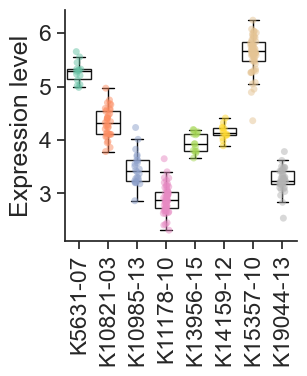

In [73]:
# -- Plot gene expression across patients

obs_df = adata_raw.obs
var_df = adata_raw[:].to_df()
var_df.iloc[:, :] = adata.layers['processed']
plot_df = pd.concat([obs_df, var_df], axis=1)
feat= 'H2BC3'
plot_df['area'] = plot_df['area']*0.28
# plot_df = plot_df[plot_df['patient_id'] =='K10821-03']

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

boxplot(df=plot_df, 
        x='patient_id',
        y=feat, 
        # order = list(architecture_colormap.keys()),
        xticks_rotation = 90, 
        figsize=(3,3),
        font_scale=1.5,
        alpha = 0.5,
        s=5,
        notch = False,
        showfliers=False,
        stripplot=True,
        swarm_color=list(patient_colormap.values())
)

plt.ylabel('Expression level')

### 12.b) Gene expression accross architectures

C:\Users\fbertil\AppData\Local\Temp\ipykernel_24040\3546680334.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.stripplot(df,


Text(0, 0.5, 'Expression level')

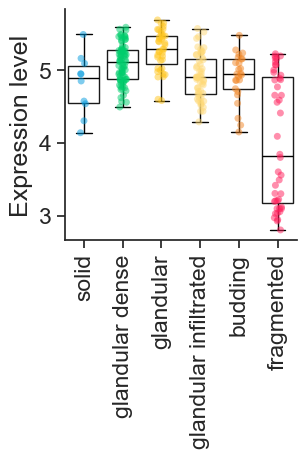

In [6]:
# -- Plot gene expression across architectures

obs_df = adata_raw.obs
var_df = adata_raw[:].to_df()
var_df.iloc[:, :] = adata.layers['processed']
plot_df = pd.concat([obs_df, var_df], axis=1)
feat= 'CDX2'
# plot_df['area'] = plot_df['area']*0.28
# plot_df = plot_df[plot_df['patient_id'] =='K10821-03']

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42


boxplot(plot_df, 
        x='architectures',
        y=feat, 
        order = list(architecture_colormap.keys()),
        font_scale=1.5,
        xticks_rotation = 90, 
        figsize=(3,3),
        alpha = 0.5,
        s=5,
        notch = False,
        showfliers=False,
        stripplot=True,
        swarm_color=list(architecture_colormap.values())
)

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\Figure3\Sup'
# out_path = os.path.join(OUT_DIR, f'{feat}_across_architectures.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')
plt.ylabel('Expression level')

### 12.c) Multiple genes expression accross patients

C:\Users\fbertil\AppData\Local\Temp\ipykernel_24040\943784450.py:37: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:w'` for the same effect.

  g = sns.boxplot(data=melted_df,


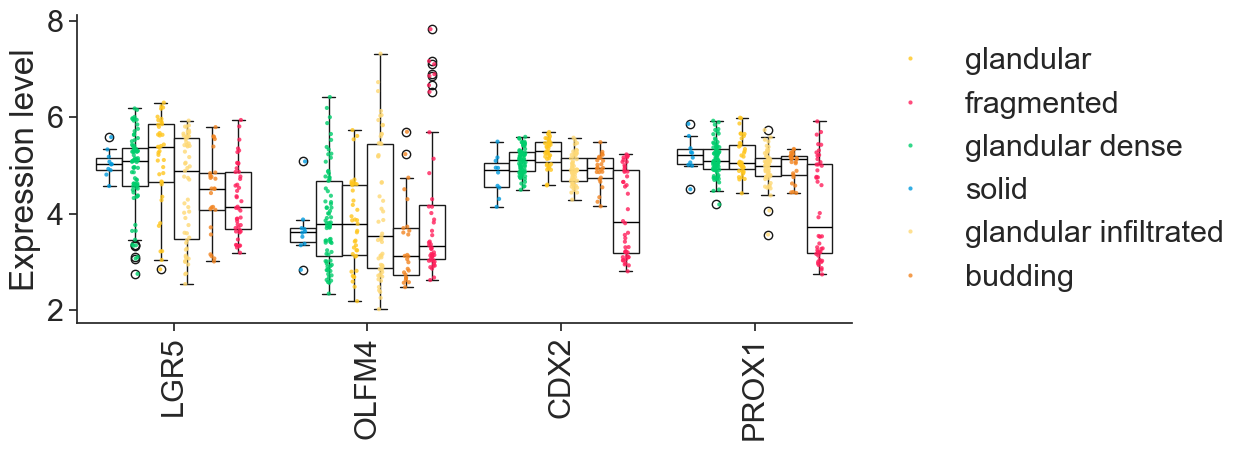

In [10]:
# -- Plot multiple genes across architectures

obs_df = adata_raw.obs
var_df = adata_raw[:].to_df()
var_df.iloc[:, :] = adata.layers['processed']
plot_df = pd.concat([obs_df, var_df], axis=1)

melted_df = pd.melt(plot_df, id_vars=['architectures'], 
                    value_vars=['LGR5','OLFM4', 'CDX2', 'PROX1'] , 
                    var_name='marker', value_name='value')




matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

plt.rcParams["figure.figsize"] = (10,4)
sns.set(font_scale = 2)
sns.set_style('white', rc={
'xtick.bottom': True,
'ytick.left': True,
    })

g = sns.stripplot(data=melted_df, 
                x='marker',
                y='value', 
                hue="architectures",
                hue_order=architecture_order,
                palette=architecture_palette,
                alpha=0.8,
                s=3,
                jitter=True,
                dodge=True
                )

g = sns.boxplot(data=melted_df, 
                x="marker", 
                y="value",
                hue="architectures",
                hue_order=architecture_order,
                color='w',
                boxprops=dict(linewidth=1, edgecolor='k',facecolor='w'),  # Set edgecolor to black
                medianprops=dict(color='black', linewidth=1),
                )

# for median in g.lines[:]:
#     median.set_color('black')  # Change the color of the median line
#     median.set_linewidth(1)  # Change
    


handles, labels = plt.gca().get_legend_handles_labels()
unique_labels = list(set(labels))
handles = [handles[labels.index(label)] for label in unique_labels]


plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, title='')
plt.ylabel('Expression level')

g.tick_params(bottom=True)

plt.xticks(rotation=90)
plt.xlabel('')
sns.despine()

# OUT_DIR = r'C:\Users\fbertil\CRC Figures\Figure3\Sup'
# out_path = os.path.join(OUT_DIR, f'shapes_across_architectures.pdf')
# plt.savefig(out_path, format='pdf', bbox_inches='tight')


In [19]:
adata_raw.obs.columns

Index(['slide_id', 'roi_id', 'area_fraction', 'mean_CD45', 'mean_aSMA',
       'mean_H3K9', 'mean_RNApolII', 'mean_LMNAC', 'mean_H3K9_sn',
       'mean_RNApolII_sn', 'mean_LMNAC_sn', 'lap_var', 'qc_pass', 'sample_id',
       'segment', 'patient_id', 'region', 'index', 'x_centroid', 'y_centroid',
       'x_orientation', 'y_orientation', 'major_axis', 'minor_axis',
       'perimeter', 'convex_area', 'area', 'circularity', 'roundness',
       'solidity', 'aspect_ratio', 'compactness', 'efc_ratio', 'isin_tumor',
       'X', 'Y', 'Height', 'Width', 'hollow_ratio', 'area_fraction_class',
       'mean_CD45_class', 'mean_aSMA_class', 'mean_H3K9_sn_class',
       'mean_RNApolII_sn_class', 'mean_LMNAC_sn_class', 'hollow_ratio_class',
       'circularity_class', 'solidity_class', 'patients_ordered',
       'architectures'],
      dtype='object')